# Что влияет на качество классификации у новых участников?

В [предыдущем опыте](02_reproduce_wassall_2026.ipynb) Random Forest дал около 53% средней LSO accuracy на восьми кодах `Terrain`. Здесь проверяются три изменения: отбор циклов, представление сигнала и состав каналов. Затем сравниваются результаты отдельных людей.

Пять тестовых групп зафиксированы заранее. Прибавка качества на этих группах остаётся исследовательским результатом; окончательная оценка выбранного варианта требует отдельного теста.

## 1. Данные и прежняя модель

Используются те же PS-файлы, правила обработки и 20 физических участников. P7_TT и P7_TF считаются одним человеком. Точный дубликат PS и циклы с недокументированными кодами `Terrain` исключаются по прежним правилам.

Среднее и стандартное отклонение для исторического варианта рассчитываются по всей папке записей человека. Это использует сигналы тестового человека без меток и ограничивает применение такой нормализации к новым пользователям.

In [1]:
from pathlib import Path
from datetime import datetime
from importlib.metadata import version
from time import perf_counter
import hashlib
import json
import pickle
import platform
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.signal import resample_poly
from research_graph.paths import NTNU_DIR, report_dir
from research_graph.pipelines.preprocessing import (
    SAMPLING_HZ, SOURCE_CHANNELS, FILTERED_CHANNELS, USED_CHANNELS,
    RIGHT_GROUPS, filter_imu, cadence_from_steps, person_mean_and_std,
)
from research_graph.pipelines.features import raw_and_person_channels, stride_statistics
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, roc_auc_score)

DATA_DIR = NTNU_DIR
if not (DATA_DIR / 'import_manifest.json').is_file():
    raise FileNotFoundError(f'Не найдены данные NTNU: {DATA_DIR}')
PREVIOUS_DIR = report_dir('reproduction_wassall_2026')
OUTPUT_DIR = report_dir('model_experiments')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'figures').mkdir(exist_ok=True)

manifest = json.loads((DATA_DIR / 'import_manifest.json').read_text(encoding='utf-8'))
previous_config = json.loads((PREVIOUS_DIR / 'config.json').read_text(encoding='utf-8'))
previous_comparison = pd.read_csv(PREVIOUS_DIR / 'tables' / 'article_comparison.csv')
previous_folds = pd.read_csv(PREVIOUS_DIR / 'tables' / 'fold_results.csv')
previous_cycles = pd.read_csv(PREVIOUS_DIR / 'tables' / 'cycles.csv')
assert manifest['dataset_sha256'] == previous_config['dataset_sha256']
assert previous_config['model_cycles'] == len(previous_cycles) == 9781
assert previous_config['number_of_features'] == 300
previous_lso = previous_folds.query("experiment == '8_LSO'")
previous_accuracy = previous_lso['accuracy'].mean()
assert len(previous_lso) == 5
print('Исходные CSV:', DATA_DIR)
print('Предыдущий LSO baseline:', f'{previous_accuracy:.2%}')
print('Контрольная сумма набора:', manifest['dataset_sha256'])
display(previous_comparison.round(2))

Исходные CSV: ~/research-publication-data\data\raw\ntnu
Предыдущий LSO baseline: 52.72%
Контрольная сумма набора: 920aae0f2f1e16b5018ef275888e05288f7e015d2b818f81c39a6c30e7262fa4


,Эксперимент,"Статья, %","Python, %","Разница, п.п."
0,"8 классов, LSO",56.89,52.72,-4.17
1,"8 классов, CV",83.64,82.92,-0.72
2,"6 классов, LSO",65.70,60.47,-5.23
3,"6 классов, CV",85.65,85.05,-0.60


In [2]:
FS = SAMPLING_HZ
LABELS = [1, 2, 4, 5, 6, 7, 8, 9]
FULL_CHANNELS = (['cadence_rate_hz'] + list(USED_CHANNELS) +
                 ['NPP_cadence_rate_hz'] + ['NPP_' + name for name in USED_CHANNELS])
EXPECTED_COLUMNS = list(SOURCE_CHANNELS) + ['Steps', 'Terrain', 'Turn']
LSO_GROUPS = previous_config['physical_lso_groups']
MODEL_PARAMS = dict(previous_config['model'])
MODEL_PARAMS['n_jobs'] = 4  # ограничение одновременных потоков; деревья и seed те же
assert MODEL_PARAMS['n_estimators'] == 100
assert MODEL_PARAMS['max_features'] == 7
assert MODEL_PARAMS['random_state'] == 42
HASHES = {item['path']: item['sha256'] for item in manifest['files']}
TRIAL_NAME = re.compile(r'(?P<course>[A-Za-z]+?)(?P<aid>wi|wo|w0)(?P<repeat>\d+)PS$')
ps_paths = sorted(DATA_DIR.glob('P*/*PS.csv'))
groups = sorted({path.parent.name for path in ps_paths})
people = sorted({group.split('_')[0] for group in groups}, key=lambda p: int(p[1:]))
assert len(people) == 20 and len(groups) == 21
assert sorted(person for fold in LSO_GROUPS for person in fold) == sorted(people)
print(f'Участников: {len(people)}; папок записей: {len(groups)}; PS-файлов: {len(ps_paths)}')

Участников: 20; папок записей: 21; PS-файлов: 638


### Подготовка циклов

Все варианты строятся из одного и того же непрерывного участка `Steps` в PS. Для E2 меняется только способ представления: 10 точек, 50 точек или статистики. TH добавляется лишь при построчном совпадении длины, `Steps` и `Terrain` с PS.

Коды 8/9 не переименовываются. Длительности рассчитаны при 100 Гц; истинную частоту записей P16/P19 по CSV проверить нельзя.

In [3]:
# Проверка размеров перед извлечением признаков.
assert stride_statistics(np.arange(60).reshape(2, 30)).shape == (210,)
assert resample_poly(np.ones((37, 30)), 50, 37, axis=0).shape == (50, 30)

In [4]:
rows, vectors_10, vectors_50, vectors_stats, vectors_th = [], [], [], [], []
preparation_seconds = {'10 точек': 0.0, '50 точек': 0.0, 'статистики': 0.0}
exclusions = []
pair_checks = []
for group_name in groups:
    chunks = []
    seen_hashes = {}
    for path in (item for item in ps_paths if item.parent.name == group_name):
        relative = path.relative_to(DATA_DIR).as_posix()
        digest = HASHES[relative]
        if digest in seen_hashes:
            exclusions.append({'participant': group_name.split('_')[0],
                               'recording_group': group_name, 'trial': path.stem[:-2],
                               'run': np.nan, 'reason': 'точная копия PS-файла'})
            continue
        seen_hashes[digest] = relative
        if TRIAL_NAME.fullmatch(path.stem) is None:
            raise ValueError(f'Неизвестное имя: {relative}')
        ps = pd.read_csv(path)
        if list(ps.columns) != EXPECTED_COLUMNS or ps.isna().any().any():
            raise ValueError(f'Некорректный PS: {relative}')
        steps = ps['Steps'].to_numpy()
        terrain = ps['Terrain'].to_numpy()
        cadence = cadence_from_steps(steps)
        _, ps_filtered = filter_imu(ps, right=group_name in RIGHT_GROUPS)

        th_path = path.with_name(path.stem[:-2] + 'TH.csv')
        paired = False
        th_filtered = None
        if th_path.exists():
            th = pd.read_csv(th_path)
            paired = (list(th.columns) == EXPECTED_COLUMNS and
                      len(th) == len(ps) and
                      np.array_equal(th['Steps'].to_numpy(), steps) and
                      np.array_equal(th['Terrain'].to_numpy(), terrain))
            if paired:
                _, th_filtered = filter_imu(th, right=group_name in RIGHT_GROUPS)
        pair_checks.append({'participant': group_name.split('_')[0],
                            'recording_group': group_name,
                            'trial': path.stem[:-2], 'paired': paired,
                            'ps_samples': len(ps),
                            'th_samples': len(th) if th_path.exists() else np.nan})
        chunks.append({'relative': relative, 'trial': path.stem[:-2],
                       'steps': steps, 'terrain': terrain, 'cadence': cadence,
                       'ps': ps_filtered, 'th': th_filtered, 'paired': paired,
                       'bounds': np.flatnonzero(np.r_[True, steps[1:] != steps[:-1], True])})

    ps_all = np.vstack([np.column_stack((chunk['cadence'], chunk['ps']))
                        for chunk in chunks])
    ps_mean, ps_sd = person_mean_and_std(ps_all)
    th_chunks = [chunk for chunk in chunks if chunk['paired']]
    if th_chunks:
        th_all = np.vstack([np.column_stack((chunk['cadence'], chunk['th']))
                            for chunk in th_chunks])
        th_mean, th_sd = person_mean_and_std(th_all)
    for chunk in chunks:
        ps_selected = raw_and_person_channels(chunk['ps'], chunk['cadence'], ps_mean, ps_sd)
        th_selected = (raw_and_person_channels(chunk['th'], chunk['cadence'], th_mean, th_sd)
                       if chunk['paired'] else None)
        bounds = chunk['bounds']
        for run in range(len(bounds) - 1):
            start, stop = int(bounds[run]), int(bounds[run + 1])
            identity = {'participant': group_name.split('_')[0],
                        'recording_group': group_name, 'path': chunk['relative'],
                        'trial': chunk['trial'], 'step': chunk['steps'][start],
                        'run': run, 'samples': stop - start}
            terrain_values = chunk['terrain'][start:stop]
            if stop - start < 3 or not np.isfinite(identity['step']) or identity['step'] < 1:
                exclusions.append({**identity, 'reason': 'короткий или неверный Steps'})
                continue
            if not np.isin(terrain_values, LABELS).all():
                exclusions.append({**identity, 'reason': 'недокументированный Terrain'})
                continue
            labels, label_counts = np.unique(terrain_values, return_counts=True)
            terrain_code = int(labels[np.argmax(label_counts)])
            window = ps_selected[start:stop]
            begin = perf_counter()
            sample_10 = resample_poly(window, 10, stop - start, axis=0)
            preparation_seconds['10 точек'] += perf_counter() - begin
            begin = perf_counter()
            sample_50 = resample_poly(window, 50, stop - start, axis=0)
            preparation_seconds['50 точек'] += perf_counter() - begin
            begin = perf_counter()
            stats = stride_statistics(window)
            preparation_seconds['статистики'] += perf_counter() - begin
            if sample_10.shape != (10, 30) or sample_50.shape != (50, 30):
                raise AssertionError('Неожиданная форма ресемплирования')
            rows.append({**identity, 'terrain': terrain_code,
                         'duration_s': (stop - start) / FS,
                         'th_paired': chunk['paired']})
            vectors_10.append(sample_10.ravel().astype('float32'))
            vectors_50.append(sample_50.ravel().astype('float32'))
            vectors_stats.append(stats.astype('float32'))
            if th_selected is None:
                vectors_th.append(None)
            else:
                th_sample = resample_poly(th_selected[start:stop], 10,
                                          stop - start, axis=0)
                vectors_th.append(th_sample.ravel().astype('float32'))

cycles = pd.DataFrame(rows)
excluded = pd.DataFrame(exclusions)
pair_table = pd.DataFrame(pair_checks)
X10 = np.stack(vectors_10)
X50 = np.stack(vectors_50)
Xstats = np.stack(vectors_stats)
y = cycles['terrain'].to_numpy(dtype=int)
physical_ids = cycles['participant'].to_numpy()
assert X10.shape == (9781, 300) and X50.shape == (9781, 1500)
assert Xstats.shape == (9781, 210)
assert len(cycles) == len(previous_cycles)
identity_columns = ['participant', 'recording_group', 'path', 'trial', 'step', 'run', 'samples', 'terrain']
pd.testing.assert_frame_equal(cycles[identity_columns].reset_index(drop=True),
                              previous_cycles[identity_columns].reset_index(drop=True),
                              check_dtype=False)
assert 'Terrain' not in FULL_CHANNELS and 'participant' not in FULL_CHANNELS
display(pd.DataFrame({'Показатель': ['Людей', 'Циклов', 'PS+TH совпали по строкам',
                                     'PS+TH не совпали', 'Исключённых сегментов/копий'],
                      'Значение': [len(people), len(cycles), int(pair_table['paired'].sum()),
                                  int((~pair_table['paired']).sum()), len(excluded)]}))
display(excluded['reason'].value_counts().rename_axis('Причина').to_frame('Число'))

,Показатель,Значение
0,Людей,20
1,Циклов,9781
2,PS+TH совпали по строкам,637
3,PS+TH не совпали,0
4,Исключённых сегментов/копий,3


,Число
Причина,
недокументированный Terrain,2
точная копия PS-файла,1


In [5]:
display(Markdown(
    f'На **{len(cycles):,} циклах** и **{len(people)} людях** метаданные каждого '
    'наблюдения совпали с предыдущим опытом. У PS и TH построчно совпали '
    f'**{int(pair_table["paired"].sum())} из {len(pair_table)}** проверенных записей. '
    'Поэтому опыт с двумя датчиками ниже использует только подтверждённые пары; '
    'если они покрывают не все циклы, сравнение проводится с PS на той же подвыборке.'
))

На **9,781 циклах** и **20 людях** метаданные каждого наблюдения совпали с предыдущим опытом. У PS и TH построчно совпали **637 из 637** проверенных записей. Поэтому опыт с двумя датчиками ниже использует только подтверждённые пары; если они покрывают не все циклы, сравнение проводится с PS на той же подвыборке.

## 2. Схема сравнения

В пяти LSO-фолдах тестовые люди не меняются. E1-B и E1-C удаляют циклы только из обучения, поэтому их предсказания относятся к тому же тесту. E1-D — другая, шестиклассовая задача.

Используются прежние параметры Random Forest и seed. Сохраняются метрики, предсказания, время и размер модели. ROC-AUC OvR рассчитывается только для фолдов со всеми нужными классами.

In [6]:
splits = []
assignment = np.full(len(cycles), -1, dtype=int)
for fold, held_out in enumerate(LSO_GROUPS, start=1):
    test = np.flatnonzero(np.isin(physical_ids, held_out))
    train = np.flatnonzero(~np.isin(physical_ids, held_out))
    assert len(test) and len(train)
    assert set(physical_ids[train]).isdisjoint(physical_ids[test])
    assert not np.any(assignment[test] != -1)
    assignment[test] = fold
    splits.append((train, test))
assert (assignment > 0).all()
assert assignment[cycles['participant'].eq('P7').to_numpy()].min() == 2
assert assignment[cycles['participant'].eq('P7').to_numpy()].max() == 2
fingerprints = np.array([hashlib.sha256(row.tobytes()).hexdigest() for row in X10])
for train, test in splits:
    assert set(fingerprints[train]).isdisjoint(fingerprints[test])
fold_membership = cycles[['participant', 'recording_group', 'trial', 'step', 'run']].copy()
fold_membership['fold'] = assignment
display(pd.DataFrame([{'Fold': fold, 'Участники': ', '.join(people_in_fold),
                       'Тестовых циклов': int((assignment == fold).sum())}
                      for fold, people_in_fold in enumerate(LSO_GROUPS, start=1)]))

,Fold,Участники,Тестовых циклов
0,1,"P6, P3, P16, P11",2391
1,2,"P7, P17, P14, P8",2299
2,3,"P2, P4, P12, P13",1794
3,4,"P9, P20, P10, P18",1879
4,5,"P5, P19, P15, P1",1418


In [7]:
FOLD_ROWS = []
PREDICTION_FRAMES = []
MODEL_SIZES = []

def evaluate(name, features, labels=y, train_allowed=None, test_allowed=None,
             class_order=LABELS):
    '''Одна заранее заданная конфигурация на пяти неизменных группах.'''
    if train_allowed is None:
        train_allowed = np.ones(len(cycles), dtype=bool)
    if test_allowed is None:
        test_allowed = np.ones(len(cycles), dtype=bool)
    if features.shape[0] != len(cycles):
        raise ValueError('Число строк признаков не совпало с циклами')
    if not np.isfinite(features[train_allowed | test_allowed]).all():
        raise ValueError('В признаках есть NaN/Inf')
    fold_rows = []
    pred_frames = []
    for fold, (base_train, base_test) in enumerate(splits, start=1):
        train = base_train[train_allowed[base_train]]
        test = base_test[test_allowed[base_test]]
        assert len(train) > 0 and len(test) > 0
        assert set(physical_ids[train]).isdisjoint(physical_ids[test])
        assert set(fingerprints[train]).isdisjoint(fingerprints[test])
        model = RandomForestClassifier(**MODEL_PARAMS)
        start = perf_counter()
        model.fit(features[train], labels[train])
        fit_seconds = perf_counter() - start
        start = perf_counter()
        predicted = model.predict(features[test])
        predict_seconds = perf_counter() - start
        true = labels[test]
        model_size_bytes = len(pickle.dumps(model, protocol=5))
        roc_auc = np.nan
        if (set(class_order) == set(np.unique(true)) == set(model.classes_)):
            probabilities = model.predict_proba(features[test])
            roc_auc = roc_auc_score(true, probabilities, labels=class_order,
                                    multi_class='ovr', average='macro')
        result = {'experiment': name, 'fold': fold,
                  'train_cycles': len(train), 'test_cycles': len(test),
                  'features': features.shape[1],
                  'accuracy': accuracy_score(true, predicted),
                  'macro_f1': f1_score(true, predicted, labels=class_order,
                                       average='macro', zero_division=0),
                  'balanced_accuracy': balanced_accuracy_score(true, predicted),
                  'roc_auc_ovr': roc_auc,
                  'fit_seconds': fit_seconds, 'predict_seconds': predict_seconds,
                  'model_size_bytes': model_size_bytes}
        fold_rows.append(result)
        held_out = cycles.iloc[test][['participant', 'recording_group',
                                      'trial', 'step', 'run']].copy()
        held_out['experiment'] = name
        held_out['fold'] = fold
        held_out['true'] = true
        held_out['predicted'] = predicted
        pred_frames.append(held_out)
        print(f'{name} · fold {fold}: accuracy {result["accuracy"]:.1%}, '
              f'macro-F1 {result["macro_f1"]:.3f}, test {len(test)}', flush=True)
    folds = pd.DataFrame(fold_rows)
    predictions = pd.concat(pred_frames, ignore_index=True)
    FOLD_ROWS.append(folds)
    PREDICTION_FRAMES.append(predictions)
    return folds, predictions

def summary_table(folds):
    '''Среднее пяти внешних фолдов, а не общая доля верных циклов.'''
    return {'Конфигурация': folds['experiment'].iloc[0],
            'Train, среднее': folds['train_cycles'].mean(),
            'Test, среднее': folds['test_cycles'].mean(),
            'Признаков': int(folds['features'].iloc[0]),
            'Accuracy': folds['accuracy'].mean(),
            'Macro-F1': folds['macro_f1'].mean(),
            'Balanced accuracy': folds['balanced_accuracy'].mean(),
            'Обучение, с': folds['fit_seconds'].mean(),
            'Предсказание, мс': 1000 * folds['predict_seconds'].mean(),
            'Размер модели, МБ': folds['model_size_bytes'].mean() / 2**20,
            'ROC-AUC: фолдов': int(folds['roc_auc_ovr'].notna().sum()),
            'ROC-AUC OvR': folds['roc_auc_ovr'].mean()}

def plot_metrics(frame, names, title, filename):
    selected = frame.set_index('Конфигурация').loc[names]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), sharey=True)
    for ax, metric in zip(axes, ['Accuracy', 'Macro-F1', 'Balanced accuracy']):
        ax.barh(selected.index, selected[metric], color='#467aa5')
        ax.set(xlim=(0, 1), xlabel=metric, title=metric)
        ax.grid(axis='x', alpha=.2)
    fig.suptitle(title)
    fig.tight_layout()
    display(fig)
    fig.savefig(OUTPUT_DIR / 'figures' / f'{filename}.png', dpi=160)
    fig.savefig(OUTPUT_DIR / 'figures' / f'{filename}.svg')
    plt.close(fig)

def show_difference(table, candidate, baseline='E1-A: baseline'):
    indexed = table.set_index('Конфигурация')
    change = indexed.loc[candidate, ['Accuracy', 'Macro-F1', 'Balanced accuracy']] - \
             indexed.loc[baseline, ['Accuracy', 'Macro-F1', 'Balanced accuracy']]
    return change

## 3. E1 — техническая очистка

E1-B исключает из обучения циклы короче 0,4 с и длиннее 3 с. E1-C исключает из обучения P16/P19 из-за вопросов к временному масштабу, но сохраняет их в тесте. E1-D оставляет коды 1, 2, 4, 5, 6, 7 и оценивается отдельно.

Дубликат PS и коды 0/99 обрабатываются одинаково во всех вариантах. OS/TR в модель не входят.

In [8]:
qc_ok = cycles['samples'].between(40, 300, inclusive='both').to_numpy()
timing_ok = ~np.isin(physical_ids, ['P16', 'P19'])
confirmed = np.isin(y, [1, 2, 4, 5, 6, 7])
qc_exclusions = cycles.loc[~qc_ok,
                           ['participant', 'recording_group', 'trial', 'step',
                            'run', 'samples', 'duration_s']].copy()
qc_exclusions['reason'] = np.where(qc_exclusions['samples'] < 40,
                                    'меньше 0,4 с', 'больше 3 с')
print('Подозрительных по длительности циклов:', len(qc_exclusions))
display(qc_exclusions['reason'].value_counts().to_frame('Циклов'))
display(cycles.loc[~timing_ok].groupby('participant').size().to_frame('Циклов вне train'))
print('Циклов с кодами 8/9:', int((~confirmed).sum()))

Подозрительных по длительности циклов: 98


,Циклов
reason,
больше 3 с,87
"меньше 0,4 с",11


,Циклов вне train
participant,
P16,117
P19,217


Циклов с кодами 8/9: 2418


E1-A: baseline · fold 1: accuracy 53.2%, macro-F1 0.475, test 2391


E1-A: baseline · fold 2: accuracy 55.0%, macro-F1 0.545, test 2299


E1-A: baseline · fold 3: accuracy 59.4%, macro-F1 0.617, test 1794


E1-A: baseline · fold 4: accuracy 57.8%, macro-F1 0.596, test 1879


E1-A: baseline · fold 5: accuracy 38.2%, macro-F1 0.292, test 1418


...

E1-D: без кодов 8/9 · fold 2: accuracy 67.1%, macro-F1 0.652, test 1764


E1-D: без кодов 8/9 · fold 3: accuracy 70.7%, macro-F1 0.720, test 1318


E1-D: без кодов 8/9 · fold 4: accuracy 68.2%, macro-F1 0.681, test 1396


E1-D: без кодов 8/9 · fold 5: accuracy 51.4%, macro-F1 0.387, test 1080


,Конфигурация,"Train, среднее","Test, среднее",Accuracy,Macro-F1,Balanced accuracy
0,E1-A: baseline,7824.8,1956.2,0.527,0.505,0.508
1,E1-B: stride QC,7746.4,1956.2,0.519,0.498,0.502
2,E1-C: без P16/P19 в train,7557.6,1956.2,0.515,0.495,0.500
3,E1-D: без кодов 8/9,5890.4,1472.6,0.648,0.611,0.604


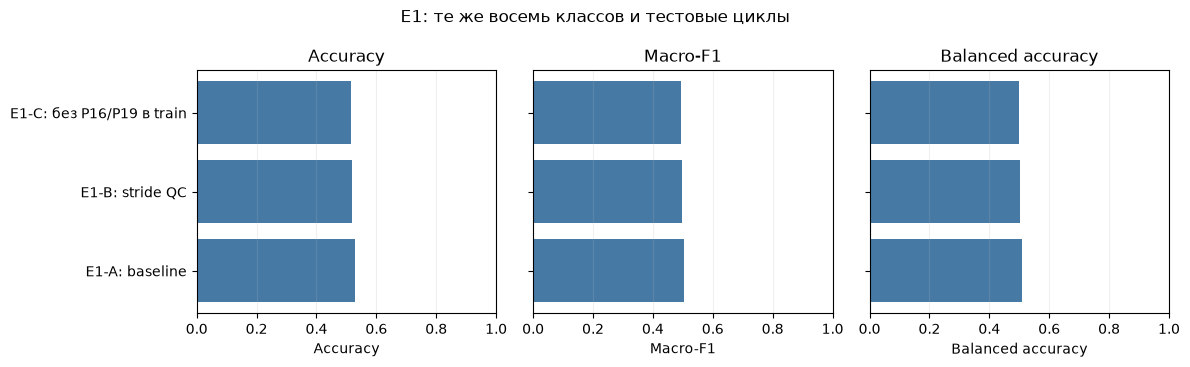

In [9]:
baseline_folds, baseline_pred = evaluate('E1-A: baseline', X10)
baseline_delta = np.abs(baseline_folds['accuracy'].to_numpy() -
                        previous_lso.sort_values('fold')['accuracy'].to_numpy())
assert baseline_delta.max() < 1e-10, 'Новый baseline отличается от сохранённого'
qc_folds, qc_pred = evaluate('E1-B: stride QC', X10, train_allowed=qc_ok)
timing_folds, timing_pred = evaluate('E1-C: без P16/P19 в train', X10,
                                    train_allowed=timing_ok)
label_folds, label_pred = evaluate('E1-D: без кодов 8/9', X10,
                                  train_allowed=confirmed, test_allowed=confirmed,
                                  class_order=[1, 2, 4, 5, 6, 7])
assert np.array_equal(baseline_pred[['participant', 'trial', 'step', 'run']].to_numpy(),
                      qc_pred[['participant', 'trial', 'step', 'run']].to_numpy())
assert np.array_equal(baseline_pred[['participant', 'trial', 'step', 'run']].to_numpy(),
                      timing_pred[['participant', 'trial', 'step', 'run']].to_numpy())
e1_table = pd.DataFrame([summary_table(folds) for folds in
                         [baseline_folds, qc_folds, timing_folds, label_folds]])
display(e1_table[['Конфигурация', 'Train, среднее', 'Test, среднее',
                  'Accuracy', 'Macro-F1', 'Balanced accuracy']].round(3))
plot_metrics(e1_table.iloc[:3], e1_table['Конфигурация'].iloc[:3].tolist(),
             'E1: те же восемь классов и тестовые циклы', '01_e1_quality')

In [10]:
qc_change = show_difference(e1_table, 'E1-B: stride QC')
timing_change = show_difference(e1_table, 'E1-C: без P16/P19 в train')
qc_people = pd.concat([baseline_pred, qc_pred]).groupby(
    ['experiment', 'participant']).apply(
        lambda part: accuracy_score(part['true'], part['predicted']),
        include_groups=False).unstack(0)
qc_people['изменение'] = qc_people['E1-B: stride QC'] - qc_people['E1-A: baseline']
display(Markdown(
    f'Отбор по длительности удалил из обучения **{len(qc_exclusions)}** циклов '
    f'во всём наборе. На прежних тестовых циклах изменение средней accuracy '
    f'составило **{100 * qc_change["Accuracy"]:+.2f} п.п.**, macro-F1 '
    f'**{qc_change["Macro-F1"]:+.3f}**. Положительное изменение accuracy '
    f'наблюдалось у **{int((qc_people["изменение"] > 0).sum())} из 20** людей. '
    f'Исключение P16/P19 только из train изменило accuracy на '
    f'**{100 * timing_change["Accuracy"]:+.2f} п.п.**. E1-D имеет иной набор классов '
    'и не служит доказательством улучшения исходной задачи.'
))

Отбор по длительности удалил из обучения **98** циклов во всём наборе. На прежних тестовых циклах изменение средней accuracy составило **-0.87 п.п.**, macro-F1 **-0.007**. Положительное изменение accuracy наблюдалось у **7 из 20** людей. Исключение P16/P19 только из train изменило accuracy на **-1.19 п.п.**. E1-D имеет иной набор классов и не служит доказательством улучшения исходной задачи.

## 4. E2 — представление цикла

Для тех же 9781 циклов сравниваются 10 точек (300 признаков), 50 точек (1500) и семь статистик каждого канала (210). Отдельно измеряется время подготовки вектора, обучения и предсказания. Чтение CSV и фильтрация одинаковы для всех трёх вариантов и в это время не входят.

E2-B: 50 точек · fold 1: accuracy 50.4%, macro-F1 0.446, test 2391


E2-B: 50 точек · fold 2: accuracy 55.9%, macro-F1 0.550, test 2299


E2-B: 50 точек · fold 3: accuracy 59.4%, macro-F1 0.606, test 1794


E2-B: 50 точек · fold 4: accuracy 55.3%, macro-F1 0.570, test 1879


E2-B: 50 точек · fold 5: accuracy 39.6%, macro-F1 0.276, test 1418


...

E2-C: статистики · fold 2: accuracy 53.1%, macro-F1 0.524, test 2299


E2-C: статистики · fold 3: accuracy 55.7%, macro-F1 0.562, test 1794


E2-C: статистики · fold 4: accuracy 54.1%, macro-F1 0.556, test 1879


E2-C: статистики · fold 5: accuracy 48.2%, macro-F1 0.439, test 1418


,Конфигурация,Признаков,Accuracy,Macro-F1,Balanced accuracy,"Подготовка, мс/цикл","Обучение, с","Предсказание, мс","Размер модели, МБ"
0,E1-A: baseline,300,0.527,0.505,0.508,0.502,1.215,37.246,30.935
1,E2-B: 50 точек,1500,0.521,0.490,0.501,0.345,1.206,35.404,31.308
2,E2-C: статистики,210,0.522,0.506,0.510,0.283,1.012,26.707,31.425


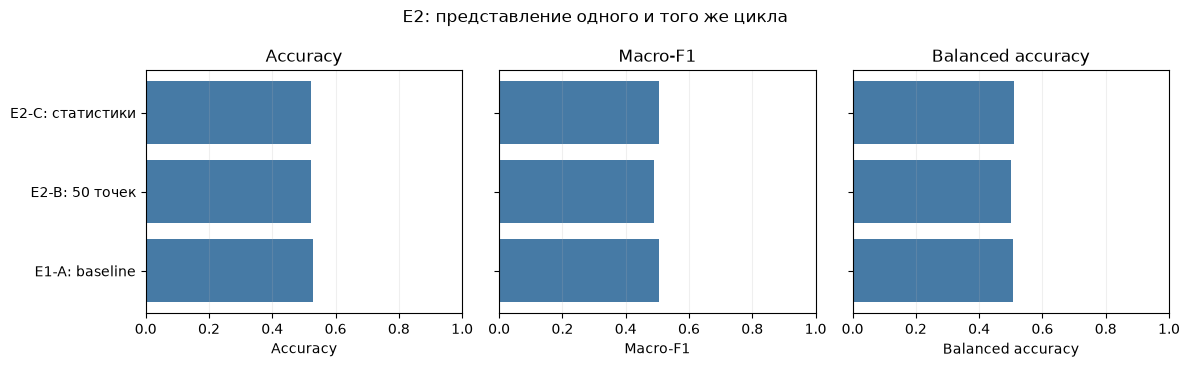

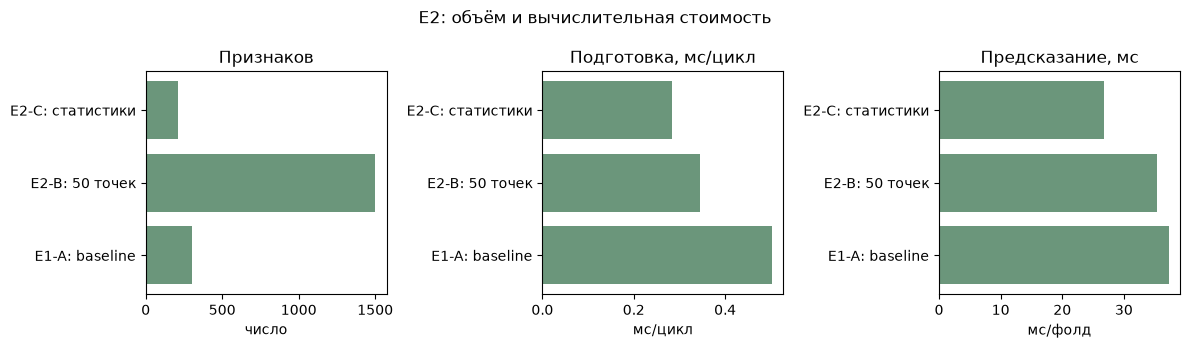

In [11]:
fifty_folds, fifty_pred = evaluate('E2-B: 50 точек', X50)
stats_folds, stats_pred = evaluate('E2-C: статистики', Xstats)
e2_table = pd.DataFrame([summary_table(folds) for folds in
                         [baseline_folds, fifty_folds, stats_folds]])
e2_table['Подготовка, мс/цикл'] = [
    1000 * preparation_seconds[name] / len(cycles)
    for name in ['10 точек', '50 точек', 'статистики']]
display(e2_table[['Конфигурация', 'Признаков', 'Accuracy', 'Macro-F1',
                  'Balanced accuracy', 'Подготовка, мс/цикл',
                  'Обучение, с', 'Предсказание, мс',
                  'Размер модели, МБ']].round(3))
plot_metrics(e2_table, e2_table['Конфигурация'].tolist(),
             'E2: представление одного и того же цикла', '02_e2_representation')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column, unit in zip(axes,
    ['Признаков', 'Подготовка, мс/цикл', 'Предсказание, мс'],
    ['число', 'мс/цикл', 'мс/фолд']):
    ax.barh(e2_table['Конфигурация'], e2_table[column], color='#6b967b')
    ax.set(xlabel=unit, title=column)
fig.suptitle('E2: объём и вычислительная стоимость')
fig.tight_layout()
display(fig)
fig.savefig(OUTPUT_DIR / 'figures' / '03_e2_cost.png', dpi=160)
fig.savefig(OUTPUT_DIR / 'figures' / '03_e2_cost.svg')
plt.close(fig)

In [12]:
best_e2 = e2_table.loc[e2_table['Macro-F1'].idxmax()]
simple = e2_table.set_index('Конфигурация').loc['E2-C: статистики']
base = e2_table.set_index('Конфигурация').loc['E1-A: baseline']
display(Markdown(
    f'Наибольший средний macro-F1 в E2 получил вариант **{best_e2["Конфигурация"]}** '
    f'({best_e2["Macro-F1"]:.3f}). Статистики изменили macro-F1 относительно '
    f'10 точек на **{simple["Macro-F1"] - base["Macro-F1"]:+.3f}**, '
    f'а число признаков — с **{int(base["Признаков"])}** до '
    f'**{int(simple["Признаков"])}**. Среднее время предсказания одного '
    f'тестового фолда: **{simple["Предсказание, мс"]:.1f} мс** против '
    f'**{base["Предсказание, мс"]:.1f} мс**. Эти времена относятся к '
    'конкретному компьютеру и повторного замера, поэтому важнее порядок величин, '
    'чем небольшие разницы.'
))

Наибольший средний macro-F1 в E2 получил вариант **E2-C: статистики** (0.506). Статистики изменили macro-F1 относительно 10 точек на **+0.001**, а число признаков — с **300** до **210**. Среднее время предсказания одного тестового фолда: **26.7 мс** против **37.2 мс**. Эти времена относятся к конкретному компьютеру и повторного замера, поэтому важнее порядок величин, чем небольшие разницы.

## 5. E3 — каналы и второй датчик

E3-A использует ускорение и гироскоп PS. E3-B добавляет свободное ускорение. E3-C — полный набор PS с магнитометром, результирующими величинами и частотой циклов. E3-D добавляет TH после проверки соответствия записей. Все варианты используют 10 точек и прежние параметры леса.

Если не для каждого PS есть подходящий TH, сравнение проводится на общей парной подвыборке. OS/TR не используются из-за совпадений, обнаруженных при EDA.

In [13]:
def channel_subset(channel_names):
    indices = [FULL_CHANNELS.index(name) for name in channel_names]
    return X10.reshape(len(cycles), 10, 30)[:, :, indices].reshape(len(cycles), -1)

ACC_GYR = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyr_X', 'Gyr_Y', 'Gyr_Z']
FREE_ACC = ['FreeAcc_E', 'FreeAcc_N', 'FreeAcc_U']
def raw_and_normalized(names):
    return names + ['NPP_' + name for name in names]

Xacc_gyr = channel_subset(raw_and_normalized(ACC_GYR))
Xacc_gyr_free = channel_subset(raw_and_normalized(ACC_GYR + FREE_ACC))
assert Xacc_gyr.shape == (len(cycles), 120)
assert Xacc_gyr_free.shape == (len(cycles), 180)
assert 'Terrain' not in raw_and_normalized(ACC_GYR + FREE_ACC)
paired_mask = cycles['th_paired'].to_numpy(dtype=bool)
Xps_th = np.zeros((len(cycles), 600), dtype='float32')
Xps_th[:, :300] = X10
for index, th_vector in enumerate(vectors_th):
    if th_vector is not None:
        Xps_th[index, 300:] = th_vector
assert np.isfinite(Xps_th[paired_mask]).all()
print(f'PS+TH: {paired_mask.sum()} из {len(cycles)} циклов имеют проверенную пару')

PS+TH: 9781 из 9781 циклов имеют проверенную пару


E3-A: Acc+Gyr · fold 1: accuracy 51.4%, macro-F1 0.453, test 2391


E3-A: Acc+Gyr · fold 2: accuracy 46.8%, macro-F1 0.462, test 2299


E3-A: Acc+Gyr · fold 3: accuracy 46.2%, macro-F1 0.483, test 1794


E3-A: Acc+Gyr · fold 4: accuracy 46.0%, macro-F1 0.436, test 1879


E3-A: Acc+Gyr · fold 5: accuracy 35.8%, macro-F1 0.271, test 1418


...

E3-D: PS+TH · fold 2: accuracy 59.6%, macro-F1 0.578, test 2299


E3-D: PS+TH · fold 3: accuracy 53.3%, macro-F1 0.555, test 1794


E3-D: PS+TH · fold 4: accuracy 58.0%, macro-F1 0.592, test 1879


E3-D: PS+TH · fold 5: accuracy 39.7%, macro-F1 0.306, test 1418


,Конфигурация,"Train, среднее","Test, среднее",Признаков,Accuracy,Macro-F1,Balanced accuracy,"Предсказание, мс"
0,E3-A: Acc+Gyr,7824.8,1956.2,120,0.452,0.421,0.424,30.155
1,E3-B: +FreeAcc,7824.8,1956.2,180,0.476,0.448,0.446,32.335
2,E1-A: baseline,7824.8,1956.2,300,0.527,0.505,0.508,37.246
3,E3-D: PS+TH,7824.8,1956.2,600,0.523,0.496,0.496,45.800


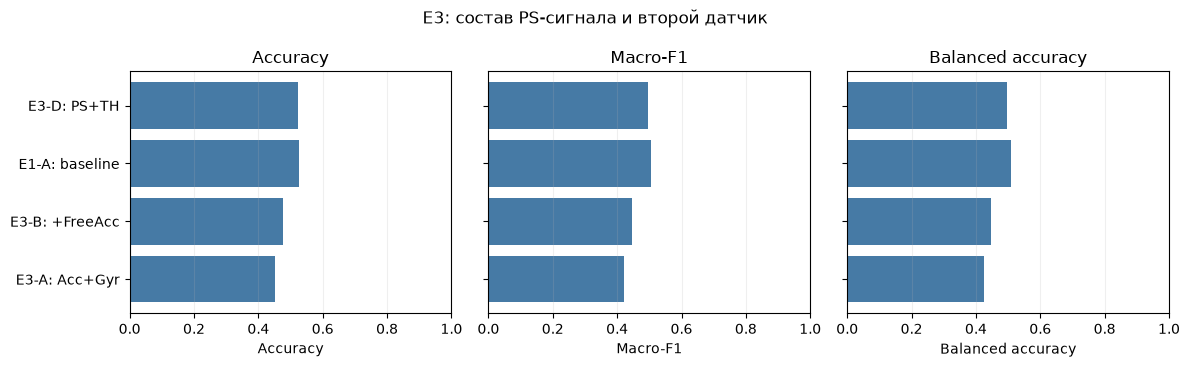

In [14]:
accgyr_folds, accgyr_pred = evaluate('E3-A: Acc+Gyr', Xacc_gyr)
free_folds, free_pred = evaluate('E3-B: +FreeAcc', Xacc_gyr_free)
if paired_mask.all():
    paired_ps_folds, paired_ps_pred = baseline_folds, baseline_pred
    paired_comparison_name = 'E1-A: baseline'
else:
    paired_ps_folds, paired_ps_pred = evaluate(
        'E3-C: PS на парных циклах', X10,
        train_allowed=paired_mask, test_allowed=paired_mask)
    paired_comparison_name = 'E3-C: PS на парных циклах'
two_sensor_folds, two_sensor_pred = evaluate(
    'E3-D: PS+TH', Xps_th,
    train_allowed=paired_mask, test_allowed=paired_mask)
assert np.array_equal(paired_ps_pred[['participant', 'trial', 'step', 'run']].to_numpy(),
                      two_sensor_pred[['participant', 'trial', 'step', 'run']].to_numpy())
e3_folds = [accgyr_folds, free_folds, baseline_folds]
if not paired_mask.all():
    e3_folds.append(paired_ps_folds)
e3_folds.append(two_sensor_folds)
e3_table = pd.DataFrame([summary_table(folds) for folds in e3_folds])
display(e3_table[['Конфигурация', 'Train, среднее', 'Test, среднее',
                  'Признаков', 'Accuracy', 'Macro-F1', 'Balanced accuracy',
                  'Предсказание, мс']].round(3))
plot_metrics(e3_table, e3_table['Конфигурация'].tolist(),
             'E3: состав PS-сигнала и второй датчик', '04_e3_channels')

In [15]:
indexed_e3 = e3_table.set_index('Конфигурация')
acc_to_full = indexed_e3.loc['E1-A: baseline', ['Accuracy', 'Macro-F1',
                                                'Balanced accuracy']] - \
              indexed_e3.loc['E3-A: Acc+Gyr', ['Accuracy', 'Macro-F1',
                                               'Balanced accuracy']]
second_sensor = indexed_e3.loc['E3-D: PS+TH', ['Accuracy', 'Macro-F1',
                                               'Balanced accuracy']] - \
                indexed_e3.loc[paired_comparison_name, ['Accuracy', 'Macro-F1',
                                                         'Balanced accuracy']]
display(Markdown(
    f'Полный PS-набор отличается от Acc+Gyr по accuracy на '
    f'**{100 * acc_to_full["Accuracy"]:+.2f} п.п.**, по macro-F1 на '
    f'**{acc_to_full["Macro-F1"]:+.3f}**. Второй датчик изменил accuracy '
    f'на **{100 * second_sensor["Accuracy"]:+.2f} п.п.** и macro-F1 на '
    f'**{second_sensor["Macro-F1"]:+.3f}** относительно PS на **той же** '
    f'парной выборке ({paired_mask.sum()} циклов). Использование TH требует '
    'дополнительного датчика и синхронизации; время модели не учитывает эти '
    'затраты на сбор сигнала.'
))

Полный PS-набор отличается от Acc+Gyr по accuracy на **+7.50 п.п.**, по macro-F1 на **+0.084**. Второй датчик изменил accuracy на **-0.40 п.п.** и macro-F1 на **-0.009** относительно PS на **той же** парной выборке (9781 циклов). Использование TH требует дополнительного датчика и синхронизации; время модели не учитывает эти затраты на сбор сигнала.

## 6. Разброс по участникам

Предсказания пяти LSO-фолдов объединяются для расчёта accuracy каждого человека. Это показывает, скрывается ли за изменением средней метрики ухудшение у отдельных участников. Независимых людей всего 20, поэтому bootstrap отдельных циклов не применяется.

,mean,median,min,max,std
experiment,,,,,
E1-A: baseline,0.488,0.518,0.229,0.702,0.135
E1-B: stride QC,0.484,0.490,0.245,0.701,0.132
E1-C: без P16/P19 в train,0.476,0.508,0.214,0.690,0.142
E2-B: 50 точек,0.489,0.537,0.224,0.693,0.138
E2-C: статистики,0.447,0.480,0.146,0.646,0.148
E3-A: Acc+Gyr,0.445,0.488,0.226,0.581,0.115
E3-B: +FreeAcc,0.469,0.512,0.203,0.631,0.121
E3-D: PS+TH,0.480,0.478,0.219,0.681,0.145


experiment,E1-A: baseline,E1-B: stride QC,E1-C: без P16/P19 в train,E2-B: 50 точек,E2-C: статистики,E3-A: Acc+Gyr,E3-B: +FreeAcc,E3-D: PS+TH
participant,,,,,,,,
P1,0.0,-0.037,-0.047,-0.023,0.220,-0.048,-0.035,-0.008
P2,0.0,-0.023,0.004,0.000,-0.077,0.005,-0.089,-0.125
P3,0.0,-0.004,-0.097,-0.057,-0.159,0.075,0.068,-0.066
P4,0.0,-0.058,-0.016,0.016,0.036,-0.242,-0.197,-0.054
P5,0.0,-0.013,-0.004,0.132,-0.120,0.077,0.026,0.111
P6,0.0,-0.022,-0.029,-0.033,0.015,-0.048,-0.072,-0.038
P7,0.0,-0.011,0.007,-0.023,0.004,-0.115,-0.050,0.071
P8,0.0,0.000,0.047,0.063,-0.049,-0.085,-0.034,0.053
P9,0.0,0.023,0.012,-0.001,0.056,-0.181,-0.156,0.013


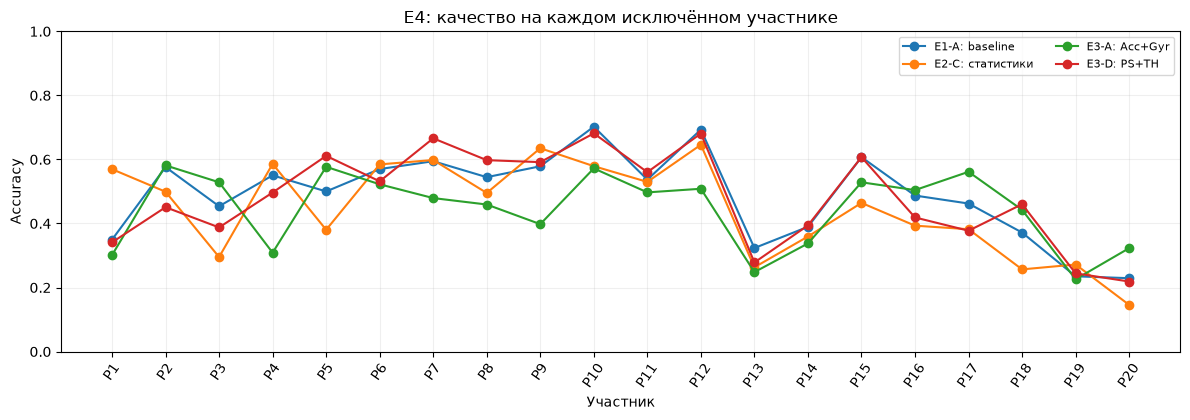

In [16]:
all_folds = pd.concat(FOLD_ROWS, ignore_index=True)
all_predictions = pd.concat(PREDICTION_FRAMES, ignore_index=True)
main_names = ['E1-A: baseline', 'E1-B: stride QC',
              'E1-C: без P16/P19 в train', 'E2-B: 50 точек',
              'E2-C: статистики', 'E3-A: Acc+Gyr',
              'E3-B: +FreeAcc', 'E3-D: PS+TH']
participant_rows = []
for (experiment, person), part in all_predictions.groupby(['experiment', 'participant']):
    labels_here = sorted(part['true'].unique().tolist())
    participant_rows.append({
        'experiment': experiment, 'participant': person,
        'test_cycles': len(part),
        'accuracy': accuracy_score(part['true'], part['predicted']),
        'macro_f1_present_classes': f1_score(
            part['true'], part['predicted'], labels=labels_here,
            average='macro', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(
            part['true'], part['predicted'])})
participant_results = pd.DataFrame(participant_rows)
e4_stats = participant_results[participant_results['experiment'].isin(main_names)].groupby(
    'experiment')['accuracy'].agg(['mean', 'median', 'min', 'max', 'std']).reindex(main_names)
display(e4_stats.round(3))
base_people = participant_results.query("experiment == 'E1-A: baseline'").set_index('participant')
participant_changes = participant_results[participant_results['experiment'].isin(main_names)].copy()
participant_changes['delta_accuracy'] = participant_changes.apply(
    lambda row: row['accuracy'] - base_people.loc[row['participant'], 'accuracy'],
    axis=1)
change_pivot = participant_changes.pivot(index='participant', columns='experiment',
                                          values='delta_accuracy').reindex(people)
display(change_pivot.round(3))
fig, ax = plt.subplots(figsize=(12, 4.3))
for name in ['E1-A: baseline', 'E2-C: статистики', 'E3-A: Acc+Gyr', 'E3-D: PS+TH']:
    part = participant_results.query('experiment == @name').set_index('participant')
    ax.plot(people, [part.loc[p, 'accuracy'] for p in people], marker='o',
            label=name)
ax.set(xlabel='Участник', ylabel='Accuracy', ylim=(0, 1),
       title='E4: качество на каждом исключённом участнике')
ax.tick_params(axis='x', labelrotation=55)
ax.grid(alpha=.2)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
display(fig)
fig.savefig(OUTPUT_DIR / 'figures' / '05_e4_people.png', dpi=160)
fig.savefig(OUTPUT_DIR / 'figures' / '05_e4_people.svg')
plt.close(fig)

In [17]:
candidate_changes = change_pivot.drop(columns=['E1-A: baseline'])
largest_worsening = candidate_changes.min().min()
worst_person, worst_variant = np.where(candidate_changes.to_numpy() == largest_worsening)
person = candidate_changes.index[worst_person[0]]
variant = candidate_changes.columns[worst_variant[0]]
display(Markdown(
    f'Средняя по людям accuracy baseline равна **{e4_stats.loc["E1-A: baseline", "mean"]:.1%}**, '
    f'минимальная — **{e4_stats.loc["E1-A: baseline", "min"]:.1%}**. '
    f'Наибольшее ухудшение относительно baseline среди показанных вариантов — '
    f'**{100 * largest_worsening:+.1f} п.п.** у **{person}** ({variant}). '
    'Значит, одних средних по фолдам недостаточно для выбора варианта: '
    'следует учитывать распределение ошибок по людям.'
))

Средняя по людям accuracy baseline равна **48.8%**, минимальная — **22.9%**. Наибольшее ухудшение относительно baseline среди показанных вариантов — **-24.2 п.п.** у **P4** (E3-A: Acc+Gyr). Значит, одних средних по фолдам недостаточно для выбора варианта: следует учитывать распределение ошибок по людям.

## 7. Сравнение вариантов

В сводной таблице E1-D отмечен как отдельная шестиклассовая задача. Остальные варианты можно сопоставлять с baseline по тем же тестовым циклам.

Победитель, выбранный по этим пяти фолдам, пока не имеет независимой оценки. Её даёт отдельная тестовая группа в следующем ноутбуке; историческое знакомство с её данными остаётся ограничением.

,Конфигурация,Сопоставимость,Признаков,Accuracy,Macro-F1,Balanced accuracy,Δ Accuracy,Δ Macro-F1,Δ Balanced accuracy,"Предсказание, мс","Размер модели, МБ"
0,E1-A: baseline,те же 8 классов и тестовые циклы,300,0.527,0.505,0.508,0.000,0.000,0.000,37.246,30.935
1,E1-B: stride QC,те же 8 классов и тестовые циклы,300,0.519,0.498,0.502,-0.009,-0.007,-0.006,41.785,30.583
2,E1-C: без P16/P19 в train,те же 8 классов и тестовые циклы,300,0.515,0.495,0.500,-0.012,-0.010,-0.008,29.769,29.727
3,E1-D: без кодов 8/9,другая задача: 6 классов,300,0.648,0.611,0.604,NaN,NaN,NaN,31.949,16.847
4,E2-B: 50 точек,те же 8 классов и тестовые циклы,1500,0.521,0.490,0.501,-0.006,-0.015,-0.007,35.404,31.308
5,E2-C: статистики,те же 8 классов и тестовые циклы,210,0.522,0.506,0.510,-0.005,0.001,0.002,26.707,31.425
6,E3-A: Acc+Gyr,те же 8 классов и тестовые циклы,120,0.452,0.421,0.424,-0.075,-0.084,-0.084,30.155,34.376
7,E3-B: +FreeAcc,те же 8 классов и тестовые циклы,180,0.476,0.448,0.446,-0.051,-0.058,-0.062,32.335,33.153
8,E3-D: PS+TH,те же 8 классов и тестовые циклы,600,0.523,0.496,0.496,-0.004,-0.009,-0.012,45.800,30.686


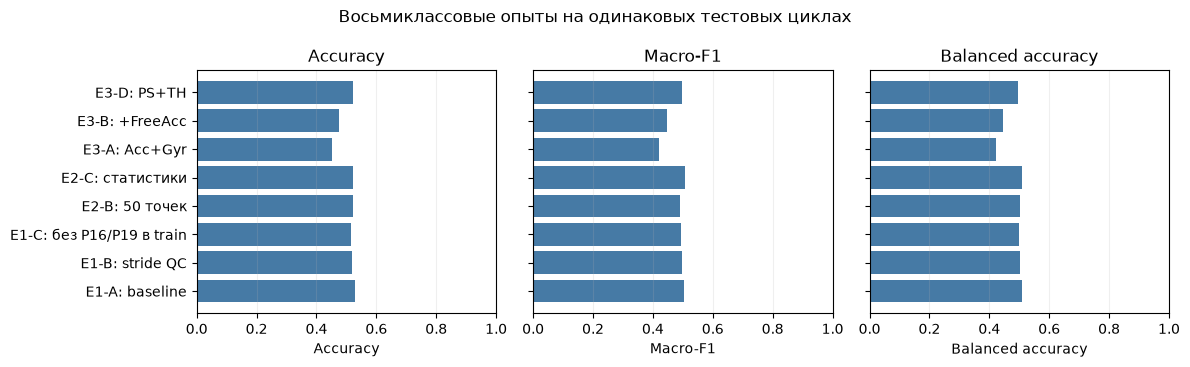

На том же тесте максимальный средний macro-F1 получил **E2-C: статистики** (0.506; изменение +0.001). Максимальная balanced accuracy — у **E2-C: статистики** (0.510), accuracy — у **E1-A: baseline** (52.7%). Это разные способы суммировать ошибки; одна строка может не быть лучшей по всем.

In [18]:
summaries = pd.DataFrame([summary_table(folds) for folds in FOLD_ROWS])
base_test_count = int(baseline_folds['test_cycles'].sum())
summaries['Сопоставимость'] = np.where(
    summaries['Конфигурация'].eq('E1-D: без кодов 8/9'),
    'другая задача: 6 классов',
    np.where(summaries['Test, среднее'] * 5 == base_test_count,
             'те же 8 классов и тестовые циклы',
             'только парные PS+TH циклы'))
baseline_metrics = summaries.set_index('Конфигурация').loc[
    'E1-A: baseline', ['Accuracy', 'Macro-F1', 'Balanced accuracy']]
for metric in ['Accuracy', 'Macro-F1', 'Balanced accuracy']:
    summaries['Δ ' + metric] = summaries[metric] - baseline_metrics[metric]
summaries.loc[summaries['Сопоставимость'] != 'те же 8 классов и тестовые циклы',
              ['Δ Accuracy', 'Δ Macro-F1', 'Δ Balanced accuracy']] = np.nan
display(summaries[['Конфигурация', 'Сопоставимость', 'Признаков',
                   'Accuracy', 'Macro-F1', 'Balanced accuracy',
                   'Δ Accuracy', 'Δ Macro-F1', 'Δ Balanced accuracy',
                   'Предсказание, мс', 'Размер модели, МБ']].round(3))
same_test = summaries.query("Сопоставимость == 'те же 8 классов и тестовые циклы'")
plot_metrics(same_test, same_test['Конфигурация'].tolist(),
             'Восьмиклассовые опыты на одинаковых тестовых циклах',
             '06_summary_same_test')
best_f1 = same_test.loc[same_test['Macro-F1'].idxmax()]
best_balanced = same_test.loc[same_test['Balanced accuracy'].idxmax()]
best_accuracy = same_test.loc[same_test['Accuracy'].idxmax()]
display(Markdown(
    f'На том же тесте максимальный средний macro-F1 получил '
    f'**{best_f1["Конфигурация"]}** ({best_f1["Macro-F1"]:.3f}; '
    f'изменение {best_f1["Δ Macro-F1"]:+.3f}). Максимальная balanced accuracy '
    f'— у **{best_balanced["Конфигурация"]}** '
    f'({best_balanced["Balanced accuracy"]:.3f}), accuracy — у '
    f'**{best_accuracy["Конфигурация"]}** ({best_accuracy["Accuracy"]:.1%}). '
    'Это разные способы суммировать ошибки; одна строка может не быть лучшей по всем.'
))

In [19]:
candidate = best_f1['Конфигурация']
people_difference = (participant_results.query('experiment == @candidate')
                     .set_index('participant')['accuracy'] -
                     base_people['accuracy']).reindex(people)
assert people_difference.notna().all()
rng = np.random.default_rng(42)
bootstrap_means = np.array([
    rng.choice(people_difference.to_numpy(), size=len(people), replace=True).mean()
    for _ in range(5000)])
ci_low, ci_high = np.quantile(bootstrap_means, [.025, .975])
display(Markdown(
    f'Для наблюдаемого лидера по macro-F1, **{candidate}**, изменение accuracy '
    f'по **20 людям** в среднем равно **{100 * people_difference.mean():+.2f} п.п.** '
    f'Участников с улучшением: **{int((people_difference > 0).sum())}**, '
    f'с ухудшением: **{int((people_difference < 0).sum())}**. '
    f'Описательный 95% bootstrap-интервал среднего изменения при '
    f'ресемплировании **участников**, а не шагов: '
    f'**[{100 * ci_low:+.2f}; {100 * ci_high:+.2f}] п.п.**. Он не исправляет смещение от '
    'выбора лидера по тем же фолдам и не заменяет внешнюю проверку.'
))

Для наблюдаемого лидера по macro-F1, **E2-C: статистики**, изменение accuracy по **20 людям** в среднем равно **-4.10 п.п.** Участников с улучшением: **6**, с ухудшением: **14**. Описательный 95% bootstrap-интервал среднего изменения при ресемплировании **участников**, а не шагов: **[-7.63; -0.10] п.п.**. Он не исправляет смещение от выбора лидера по тем же фолдам и не заменяет внешнюю проверку.

### Ошибки классов

Для каждого варианта сохраняются матрица ошибок и recall. Если класса нет в тесте, его recall остаётся неопределённым. ROC-AUC OvR считается по вероятностям при наличии всех классов; иначе в таблице остаётся `NaN`.

In [20]:
recall_rows = []
confusion_rows = []
for name, part in all_predictions.groupby('experiment', sort=False):
    order = [1, 2, 4, 5, 6, 7] if name == 'E1-D: без кодов 8/9' else LABELS
    matrix = confusion_matrix(part['true'], part['predicted'], labels=order)
    for row_number, true_label in enumerate(order):
        total = int(matrix[row_number].sum())
        recall_rows.append({'experiment': name, 'class': true_label,
                            'test_cycles': total,
                            'recall': matrix[row_number, row_number] / total
                            if total else np.nan})
        for col_number, predicted_label in enumerate(order):
            confusion_rows.append({'experiment': name,
                                   'true': true_label,
                                   'predicted': predicted_label,
                                   'cycles': int(matrix[row_number, col_number])})
class_recall = pd.DataFrame(recall_rows)
confusion_tables = pd.DataFrame(confusion_rows)
display(class_recall.pivot(index='class', columns='experiment',
                           values='recall').round(2))
print('ROC-AUC вычислен в', int(all_folds['roc_auc_ovr'].notna().sum()),
      'из', len(all_folds), 'фолдов всех экспериментов')

experiment,E1-A: baseline,E1-B: stride QC,E1-C: без P16/P19 в train,E1-D: без кодов 8/9,E2-B: 50 точек,E2-C: статистики,E3-A: Acc+Gyr,E3-B: +FreeAcc,E3-D: PS+TH
class,,,,,,,,,
1,0.70,0.68,0.67,0.77,0.68,0.63,0.70,0.70,0.73
2,0.37,0.34,0.34,0.47,0.38,0.30,0.21,0.34,0.32
4,0.63,0.62,0.61,0.63,0.61,0.61,0.62,0.63,0.66
5,0.74,0.75,0.72,0.75,0.72,0.64,0.76,0.76,0.76
6,0.47,0.48,0.48,0.52,0.48,0.50,0.24,0.25,0.43
7,0.57,0.58,0.59,0.58,0.60,0.58,0.40,0.35,0.56
8,0.29,0.28,0.29,NaN,0.30,0.39,0.21,0.28,0.29
9,0.38,0.37,0.38,NaN,0.32,0.46,0.32,0.35,0.32


ROC-AUC вычислен в 45 из 45 фолдов всех экспериментов


In [21]:
config = {
    'date': datetime.now().astimezone().isoformat(timespec='seconds'),
    'dataset_doi': manifest['dataset_doi'],
    'dataset_sha256': manifest['dataset_sha256'],
    'source_dir': str(DATA_DIR),
    'previous_baseline_dir': str(PREVIOUS_DIR),
    'previous_lso_accuracy': float(previous_accuracy),
    'physical_lso_groups': LSO_GROUPS,
    'seed': 42,
    'sampling_hz_assumed': FS,
    'filter': 'butterworth_lowpass_order2_5Hz_filtfilt',
    'normalization': 'per_recording_group_unlabelled_signal_zscore',
    'model': MODEL_PARAMS,
    'stride_qc_samples_inclusive': [40, 300],
    'timing_sensitivity_excluded_from_train': ['P16', 'P19'],
    'label_sensitivity_classes': [1, 2, 4, 5, 6, 7],
    'channels_full': FULL_CHANNELS,
    'cycles': len(cycles),
    'people': len(people),
    'ps_th_paired_cycles': int(paired_mask.sum()),
    'python': platform.python_version(),
    'packages': {name: version(name) for name in
                 ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib',
                  'nbformat', 'nbclient']},
}
summaries.to_csv(OUTPUT_DIR / 'experiment_results.csv', index=False)
all_folds.to_csv(OUTPUT_DIR / 'fold_results.csv', index=False)
participant_results.to_csv(OUTPUT_DIR / 'participant_results.csv', index=False)
all_predictions.to_csv(OUTPUT_DIR / 'predictions.csv', index=False)
class_recall.to_csv(OUTPUT_DIR / 'class_recall.csv', index=False)
confusion_tables.to_csv(OUTPUT_DIR / 'confusion_matrices.csv', index=False)
fold_membership.to_csv(OUTPUT_DIR / 'fold_assignments.csv', index=False)
excluded.to_csv(OUTPUT_DIR / 'excluded_source_cycles.csv', index=False)
qc_exclusions.to_csv(OUTPUT_DIR / 'excluded_stride_qc.csv', index=False)
pair_table.to_csv(OUTPUT_DIR / 'ps_th_alignment.csv', index=False)
(OUTPUT_DIR / 'experiment_config.json').write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Результаты сохранены:', OUTPUT_DIR)
display(pd.Series(config['packages'], name='Версия').to_frame())

Результаты сохранены: ~/research-publication-data\artifacts\reports\model_experiments


,Версия
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0


## 8. Итог

Заключение ниже опирается на сохранённые LSO-фолды и результаты отдельных людей. Высокая CV accuracy предыдущего этапа не используется для выбора варианта, рассчитанного на новых участников.

In [22]:
base_row = same_test.set_index('Конфигурация').loc['E1-A: baseline']
winner = best_f1
display(Markdown(
    f'Baseline: accuracy **{base_row["Accuracy"]:.1%}**, '
    f'macro-F1 **{base_row["Macro-F1"]:.3f}**. '
    f'Наибольший macro-F1 среди восьмиклассовых вариантов получил '
    f'**{winner["Конфигурация"]}**: **{winner["Macro-F1"]:.3f}** '
    f'({winner["Δ Macro-F1"]:+.3f} к baseline). '
    f'Его accuracy ниже baseline у **{int((people_difference < 0).sum())} из 20** '
    'людей. Разница средних невелика и получена на тех же фолдах, '
    'по которым найден лидер. Статистические признаки остаются кандидатом, '
    'но их преимущество нужно проверить на отдельной группе людей.'
))

Baseline: accuracy **52.7%**, macro-F1 **0.505**. Наибольший macro-F1 среди восьмиклассовых вариантов получил **E2-C: статистики**: **0.506** (+0.001 к baseline). Его accuracy ниже baseline у **14 из 20** людей. Разница средних невелика и получена на тех же фолдах, по которым найден лидер. Статистические признаки остаются кандидатом, но их преимущество нужно проверить на отдельной группе людей.